In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import project_helpers_metrics as phm
import project_helpers_ga as phg

## hypothesis

1. On 2020-2026, the GA portfolio's Sharpe ratio will be higher than the baseline of 100%SPY and equal weight
2. The GA put most of the money into TLT, SPY, and GLD
bonds and gold rose while stocks fell since it is more stable in 2008
3. something that could cause my prediction to go wrong is the year that bonds and stocks both fell instead of just stocks in 2022

In [2]:
prices = pd.read_csv("data/data.csv", index_col=0, parse_dates=True)
returns = phm.daily_returns(prices)
print(returns.shape)

(5282, 7)


In [3]:
test = returns.loc['2020-01-02':'2026-10-02']
print(test.shape)

(1697, 7)


In [4]:
train = returns.loc['2005-10-03':'2019-12-31']

In [5]:
load = pd.read_csv('data/weights.csv', index_col = 0)
ga_w = load['weight']
equal_weight = np.ones(7)/7
spy_weight = np.array([0,0,0,0,1,0,0])
print(ga_w.sum(), equal_weight.sum(), spy_weight.sum())

0.9999999999999998 0.9999999999999998 1


In [6]:
#dictionary to pair the name with the following value
strategies = {
    'GA':            ga_w,
    'Equal weight':  equal_weight,
    '100% SPY':      spy_weight,
}

In [7]:
rows = {}
for name, weights in strategies.items():
    daily = phm.portfolio_returns(weights, train)
    rows[name] = {
        'Annual return':     phm.annual_return(daily),
        'Annual volatility': phm.annual_volatility(daily),
        'Sharpe':            phm.sharpe(daily),
        'Max drawdown':      phm.max_drawdown(daily)
    }

results = pd.DataFrame(rows).T
print(results.round(3))

              Annual return  Annual volatility  Sharpe  Max drawdown
GA                    0.088              0.083   1.051        -0.164
Equal weight          0.095              0.162   0.587        -0.430
100% SPY              0.106              0.187   0.565        -0.552


In [8]:
rows = {}
for name, weights in strategies.items():
    daily = phm.portfolio_returns(weights, test)
    rows[name] = {
        'Annual return':     phm.annual_return(daily),
        'Annual volatility': phm.annual_volatility(daily),
        'Sharpe':            phm.sharpe(daily),
        'Max drawdown':      phm.max_drawdown(daily)
    }

results = pd.DataFrame(rows).T
print(results.round(3))

              Annual return  Annual volatility  Sharpe  Max drawdown
GA                    0.064              0.114   0.558        -0.267
Equal weight          0.098              0.152   0.646        -0.260
100% SPY              0.164              0.200   0.817        -0.337


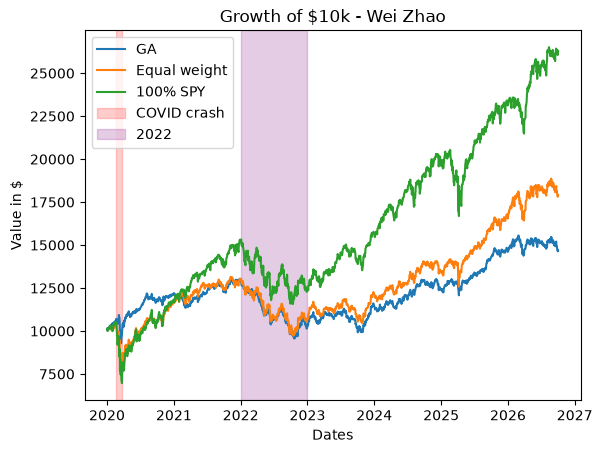

In [9]:
for name, weights in strategies.items():
    daily = phm.portfolio_returns(weights, test)
    growth = 10000 * (1 + daily).cumprod()
    plt.plot(growth.index, growth, label = name)

plt.axvspan(pd.Timestamp('2020-02-19'), pd.Timestamp('2020-03-23'), color='red', alpha=0.2, label='COVID crash') #had ai check the exact dates they landed on
plt.axvspan(pd.Timestamp('2022-01-01'), pd.Timestamp('2022-12-31'), color='purple', alpha=0.2, label='2022')
plt.title('Growth of $10k - Wei Zhao')
plt.xlabel('Dates')
plt.ylabel('Value in $')
plt.legend()
plt.savefig('figures/growth_test_period.png', dpi = 150)
plt.show()

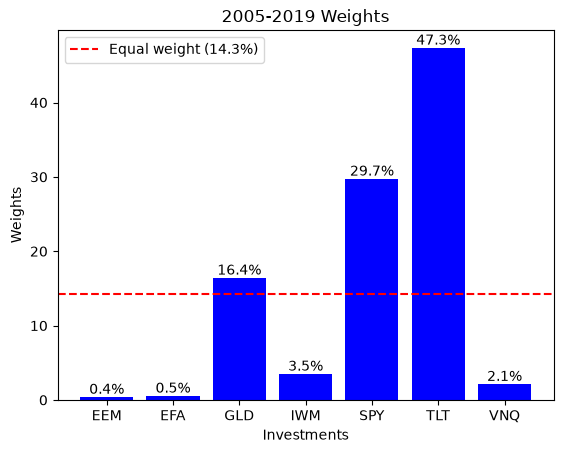

In [10]:
pct = ga_w * 100

bars = plt.bar(pct.index, pct, color='blue')
plt.bar_label(bars, fmt='%.1f%%') #percentage on top was looked up online
plt.axhline(100 / 7, linestyle='--', color='red', label='Equal weight (14.3%)')

plt.title('2005-2019 Weights')
plt.xlabel('Investments')
plt.ylabel('Weights')
plt.legend()
plt.savefig('figures/ga_weights.png', dpi=150)
plt.show()

In [11]:
results.to_csv('data/results.csv')

## Results vs. Hypothesis

**1. Sharpe ratio, 2020-2026** - not supported

Portfolio    Sharpe 
GA           0.558
equal weight 0.646
100%SPY      0.817


**2. GA weights** - supported

Fund    Weight
EEM:    0.003813
EFA:    0.005332
GLD:    0.164124
IWM:    0.034872
SPY:    0.297258
TLT:    0.473422
VNQ:    0.021179 


**3. 2022 risk**

From my possibilities of a cause of the experiment not working was that in 2022, both stocks and bonds fell was correct and correlated with the drop in returns compared to the 2005-2019 training run.

**What held up**

Even though the Sharpe was lower, the GA portfolio had the lowest volatility (11.4% vs SPY's 20%) and a smaller max drawdown (-26.7% vs -33.7%) and the risk prevention (lowest volatility) held up, but the return side did not (lowest annual return). 